In [52]:
import numpy as np

# Dataset
rng = np.random.default_rng()
inputs = rng.uniform(-5, 5, 100)
noise = rng.normal(0, 0.5, 100)
outputs = 3 * inputs + 2 + noise

In [53]:
weight = rng.random()
bias = rng.random()

In [54]:
def predictions(inputs, weight, bias):
    return weight * inputs + bias

In [55]:
# MSE
def mse_calculation(predictions, outputs):
    error = predictions - outputs
    
    return np.mean(error**2)

In [56]:
# Derivatives
def derivative_weight(predictions, outputs, inputs):
    return np.mean(2 * (predictions - outputs) * inputs)

def derivative_bias(predictions, outputs):
    return np.mean(2 * (predictions - outputs))

In [57]:
# Update weight and bias
def gradient_descent(inputs, weight, bias, outputs, learning_rate, iteration):
    loss_history = []
    for i in range(1, iteration + 1):
        predict = predictions(inputs, weight, bias)
        loss = mse_calculation(predict, outputs)
        loss_history.append(loss)

        weight -= learning_rate * derivative_weight(predict, outputs, inputs)
        bias -= learning_rate * derivative_bias(predict, outputs)

        if (i % 100 == 0):
            print("Iteration = " + str(i))
            print("Weight = " + str(weight))
            print("Bias = " + str(bias))
            print("MSE = " + str(loss))

    return weight, bias, loss_history

In [58]:
# Re-initialize weight and bias so training starts fresh
weight = rng.random()
bias = rng.random()

learning_rate = 0.01
iteration = 1000

weight, bias, loss_history = gradient_descent(inputs, weight, bias, outputs, learning_rate, iteration)

Iteration = 100
Weight = 3.016209086411591
Bias = 1.7586571853088777
MSE = 0.3360989972974496
Iteration = 200
Weight = 3.013577251294634
Bias = 1.9549650891056662
MSE = 0.28372438484162044
Iteration = 300
Weight = 3.0132273447589757
Bias = 1.9810631545314963
MSE = 0.2827987026890602
Iteration = 400
Weight = 3.013180826592511
Bias = 1.9845327500609533
MSE = 0.2827823419484764
Iteration = 500
Weight = 3.0131746422558647
Bias = 1.984994013872719
MSE = 0.28278205278460766
Iteration = 600
Weight = 3.0131738200820206
Bias = 1.9850553363819965
MSE = 0.2827820476738522
Iteration = 700
Weight = 3.0131737107784904
Bias = 1.9850634888753171
MSE = 0.28278204758352343
Iteration = 800
Weight = 3.0131736962471813
Bias = 1.9850645727048621
MSE = 0.2827820475819269
Iteration = 900
Weight = 3.013173694315323
Bias = 1.9850647167940918
MSE = 0.2827820475818987
Iteration = 1000
Weight = 3.0131736940584934
Bias = 1.9850647359499687
MSE = 0.2827820475818982


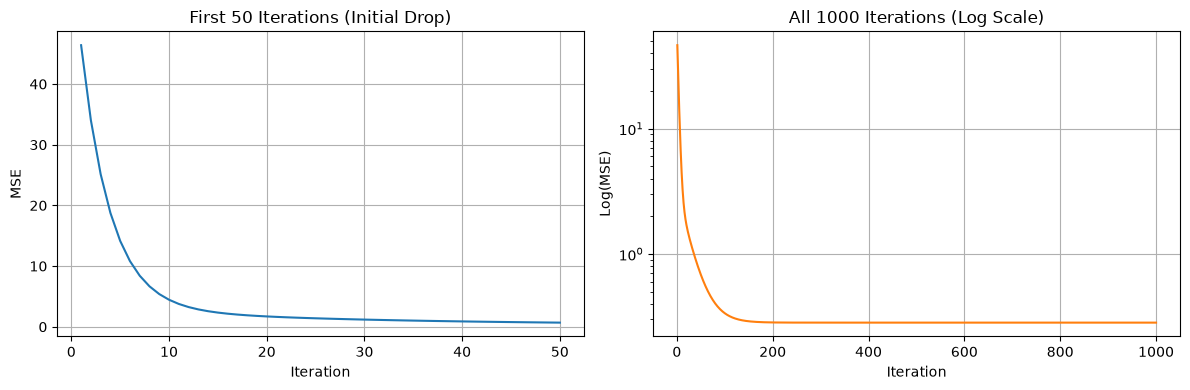

In [59]:
import matplotlib.pyplot as plt

# Visualise MSE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# First 50 iterations: rapid initial drop
ax1.plot(range(1, 51), loss_history[:50], color="tab:blue")
ax1.set_title("First 50 Iterations (Initial Drop)")
ax1.set_xlabel("Iteration")
ax1.set_ylabel("MSE")
ax1.grid(True)

# All 1000 iterations: log scale to see subtle convergence
ax2.plot(range(1, len(loss_history) + 1), loss_history, color="tab:orange")
ax2.set_yscale("log")
ax2.set_title("All 1000 Iterations (Log Scale)")
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Log(MSE)")
ax2.grid(True)

plt.tight_layout()
plt.show()

In [60]:
# central difference numerical differentiation for the weight.
def central_difference_weight(inputs, weight, bias, outputs, eps = 1e-5):
    loss_plus = mse_calculation(predictions(inputs, weight + eps, bias), outputs)
    loss_minus = mse_calculation(predictions(inputs, weight - eps, bias), outputs)

    return (loss_plus - loss_minus) / (2 * eps)

In [61]:
difference_weight = central_difference_weight(inputs, weight, bias, outputs)
print(difference_weight)

7.494005416219807e-11


In [62]:
def central_difference_bias(inputs, weight, bias, outputs, eps = 1e-5):
    loss_plus = mse_calculation(predictions(inputs, weight, bias + eps), outputs)
    loss_minus = mse_calculation(predictions(inputs, weight, bias - eps), outputs)

    return (loss_plus - loss_minus) / (2 * eps)

In [63]:
difference_bias = central_difference_bias(inputs, weight, bias, outputs)

print(difference_bias)

-5.861977570020826e-09


In [64]:
# Calculate analytical gradients
pred = predictions(inputs, weight, bias)

analytical_w = derivative_weight(pred, outputs, inputs)
analytical_b = derivative_bias(pred, outputs)

# Calculate numerical gradients
numerical_w = central_difference_weight(
    inputs, weight, bias, outputs
)

numerical_b = central_difference_bias(
    inputs, weight, bias, outputs
)

# Compare
print("Weight gradient:")
print("Analytical:", analytical_w)
print("Numerical:", numerical_w)
print("Difference:", abs(analytical_w - numerical_w))

print("\nBias gradient:")
print("Analytical:", analytical_b)
print("Numerical:", numerical_b)
print("Difference:", abs(analytical_b - numerical_b))

Weight gradient:
Analytical: 7.86642950778571e-11
Numerical: 7.494005416219807e-11
Difference: 3.724240915659036e-12

Bias gradient:
Analytical: -5.867249850410871e-09
Numerical: -5.861977570020826e-09
Difference: 5.272280390045589e-12
